In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/Mall_Customers.csv')

# Display first 5 rows
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# Select two attributes for 2D clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Display the selected data
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.cluster.hierarchy as sch

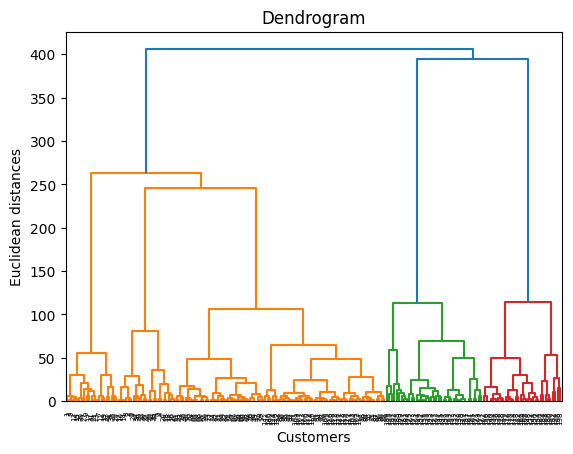

In [ ]:
# Create dendrogram using Ward's method
dendro = sch.dendrogram(sch.linkage(X, method='ward'))

plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Create the hierarchical clustering model
hc = AgglomerativeClustering(
    n_clusters=5,
    metric='euclidean',
    linkage='ward'
)

# Fit the model and predict cluster labels
y_hc = hc.fit_predict(X)

print(y_hc)

[4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4
 3 4 3 4 3 4 1 4 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1 2 0 2 0 2 1 2 0 2 0 2 0 2 0 2 1 2 0 2 1 2
 0 2 0 2 0 2 0 2 0 2 0 2 1 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0
 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2]


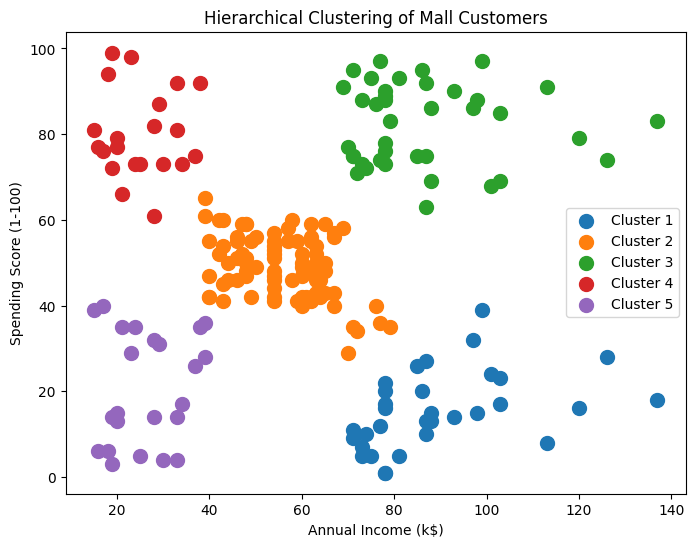

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X.iloc[y_hc == 0, 0],
    X.iloc[y_hc == 0, 1],
    s=100,
    label='Cluster 1'
)

plt.scatter(
    X.iloc[y_hc == 1, 0],
    X.iloc[y_hc == 1, 1],
    s=100,
    label='Cluster 2'
)

plt.scatter(
    X.iloc[y_hc == 2, 0],
    X.iloc[y_hc == 2, 1],
    s=100,
    label='Cluster 3'
)

plt.scatter(
    X.iloc[y_hc == 3, 0],
    X.iloc[y_hc == 3, 1],
    s=100,
    label='Cluster 4'
)

plt.scatter(
    X.iloc[y_hc == 4, 0],
    X.iloc[y_hc == 4, 1],
    s=100,
    label='Cluster 5'
)

plt.title('Hierarchical Clustering of Mall Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [ ]:
# Add the cluster labels to the dataset
df['Cluster'] = y_hc

# Display the first 10 rows
df.head(10)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4
5,6,Female,22,17,76,3
6,7,Female,35,18,6,4
7,8,Female,23,18,94,3
8,9,Male,64,19,3,4
9,10,Female,30,19,72,3


In [ ]:
# Count customers in each cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

print(cluster_counts)

Cluster
0    32
1    85
2    39
3    21
4    23
Name: count, dtype: int64


In [ ]:
# Display the dataset with cluster assignments
df[['CustomerID',
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)',
    'Cluster']].head(20)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,19,15,39,4
1,2,21,15,81,3
2,3,20,16,6,4
3,4,23,16,77,3
4,5,31,17,40,4
5,6,22,17,76,3
6,7,35,18,6,4
7,8,23,18,94,3
8,9,64,19,3,4
9,10,30,19,72,3
